## Step 1: Data Understanding & Preprocessing

In [2]:
# Load and explore the dataset

import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv(r"E:\DATA SCIENTIST\ML\repository\project\car_price_prediction.csv")

# Display first 5 rows
print("First 5 Rows:")
display(df.head())

# Check dataset shape
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types
print("\nData Types:")
print(df.dtypes)


First 5 Rows:


,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


Dataset Shape: (19237, 18)

Column Names:
['ID', 'Price', 'Levy', 'Manufacturer', 'Model', 'Prod. year', 'Category', 'Leather interior', 'Fuel type', 'Engine volume', 'Mileage', 'Cylinders', 'Gear box type', 'Drive wheels', 'Doors', 'Wheel', 'Color', 'Airbags']

Data Types:
ID                    int64
Price                 int64
Levy                 object
Manufacturer         object
Model                object
Prod. year            int64
Category             object
Leather interior     object
Fuel type            object
Engine volume        object
Mileage              object
Cylinders           float64
Gear box type        object
Drive wheels         object
Doors                object
Wheel                object
Color                object
Airbags               int64
dtype: object


In [3]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Calculate total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())


Missing Values:
ID                  0
Price               0
Levy                0
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    0
Fuel type           0
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               0
Airbags             0
dtype: int64

Total Missing Values: 0


In [4]:
# Remove 'km' and convert Mileage to numeric
df["Mileage"] = (
    df["Mileage"]
    .str.replace(" km", "", regex=False)
    .astype(float)
)

# Display the result
print(df["Mileage"].head())

# Check data type
print("\nMileage Data Type:", df["Mileage"].dtype)


0    186005.0
1    192000.0
2    200000.0
3    168966.0
4     91901.0
Name: Mileage, dtype: float64

Mileage Data Type: float64


In [5]:
from sklearn.preprocessing import LabelEncoder

# Create LabelEncoder
le = LabelEncoder()

# Convert Fuel type into numerical format
df["Fuel type"] = le.fit_transform(df["Fuel type"].astype(str))

# Display the result
print(df["Fuel type"].head())

# Display category mapping
print("\nFuel Type Mapping:")
for category, number in zip(le.classes_, le.transform(le.classes_)):
    print(category, ":", number)


0    2
1    5
2    5
3    2
4    5
Name: Fuel type, dtype: int64

Fuel Type Mapping:
CNG : 0
Diesel : 1
Hybrid : 2
Hydrogen : 3
LPG : 4
Petrol : 5
Plug-in Hybrid : 6


In [6]:
# Convert Airbags to numeric format
df["Airbags"] = pd.to_numeric(df["Airbags"], errors="coerce")

# Display the result
print(df["Airbags"].head())

# Check data type
print("\nAirbags Data Type:", df["Airbags"].dtype)


0    12
1     8
2     2
3     0
4     4
Name: Airbags, dtype: int64

Airbags Data Type: int64


In [7]:
# Check the converted columns
print(df[["Fuel type", "Mileage", "Airbags"]].head())

# Check their data types
print("\nData Types After Conversion:")
print(df[["Fuel type", "Mileage", "Airbags"]].dtypes)


   Fuel type   Mileage  Airbags
0          2  186005.0       12
1          5  192000.0        8
2          5  200000.0        2
3          2  168966.0        0
4          5   91901.0        4

Data Types After Conversion:
Fuel type      int64
Mileage      float64
Airbags        int64
dtype: object


## Step 2: Exploratory Data Analysis (EDA)

In [8]:
# Generate descriptive statistics
print("Descriptive Statistics:")

display(df.describe())


Descriptive Statistics:


,ID,Price,Prod. year,Fuel type,Mileage,Cylinders,Airbags
count,1.923700e+04,1.923700e+04,19237.000000,19237.000000,1.923700e+04,19237.000000,19237.000000
mean,4.557654e+07,1.855593e+04,2010.912824,3.432396,1.532236e+06,4.582991,6.582627
std,9.365914e+05,1.905813e+05,5.668673,1.807388,4.840387e+07,1.199933,4.320168
min,2.074688e+07,1.000000e+00,1939.000000,0.000000,0.000000e+00,1.000000,0.000000
25%,4.569837e+07,5.331000e+03,2009.000000,2.000000,7.013900e+04,4.000000,4.000000
50%,4.577231e+07,1.317200e+04,2012.000000,5.000000,1.260000e+05,4.000000,6.000000
75%,4.580204e+07,2.207500e+04,2015.000000,5.000000,1.888880e+05,4.000000,12.000000
max,4.581665e+07,2.630750e+07,2020.000000,6.000000,2.147484e+09,16.000000,16.000000


In [9]:
# Descriptive statistics of Price
print("Price Statistics:")

display(df["Price"].describe())


Price Statistics:


count    1.923700e+04
mean     1.855593e+04
std      1.905813e+05
min      1.000000e+00
25%      5.331000e+03
50%      1.317200e+04
75%      2.207500e+04
max      2.630750e+07
Name: Price, dtype: float64

In [10]:
# Summary of categorical columns
print("Categorical Data Summary:")

display(df.describe(include="object"))


Categorical Data Summary:


,Levy,Manufacturer,Model,Category,Leather interior,Engine volume,Gear box type,Drive wheels,Doors,Wheel,Color
count,19237,19237,19237,19237,19237,19237,19237,19237,19237,19237,19237
unique,559,65,1590,11,2,107,4,3,3,2,16
top,-,HYUNDAI,Prius,Sedan,Yes,2,Automatic,Front,04-May,Left wheel,Black
freq,5819,3769,1083,8736,13954,3916,13514,12874,18332,17753,5033


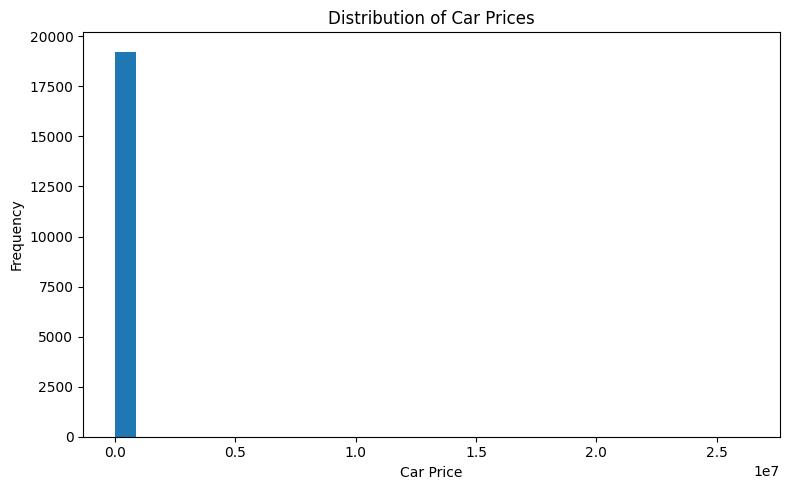

In [11]:
import matplotlib.pyplot as plt

# Histogram of car prices
plt.figure(figsize=(8, 5))

plt.hist(df["Price"], bins=30)

plt.title("Distribution of Car Prices")
plt.xlabel("Car Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


**Observation:**
1. The histogram shows the distribution of selling prices for different cars in the dataset.
2. Most cars are concentrated in the lower price ranges compared to the highest price ranges.
3. The distribution may be right-skewed because a small number of cars have very high prices.
4. The dataset may contain outliers representing cars with unusually high selling prices.

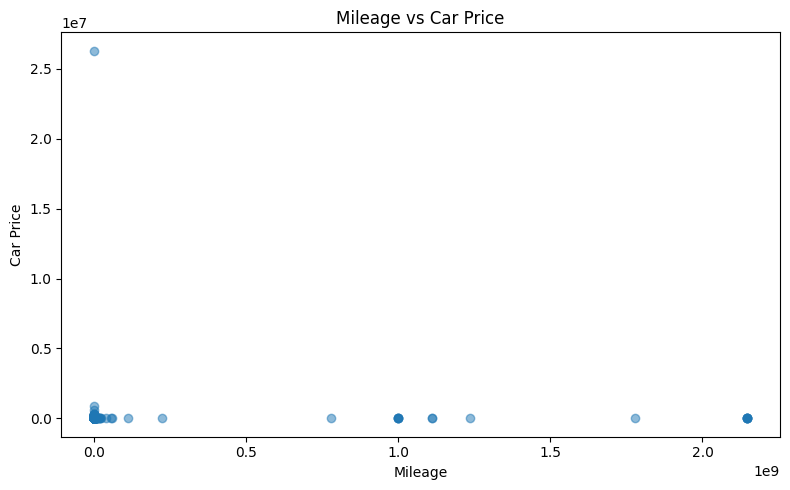

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(df["Mileage"], df["Price"], alpha=0.5)

plt.title("Mileage vs Car Price")
plt.xlabel("Mileage")
plt.ylabel("Car Price")

plt.tight_layout()
plt.show()


**Observation :**
1. The scatter plot shows the relationship between car mileage and selling price.
2. Cars with lower mileage may have higher selling prices.
3. Cars with higher mileage may have lower selling prices because of greater usage.
4. Some cars may have different prices despite having similar mileage due to differences in other car features.

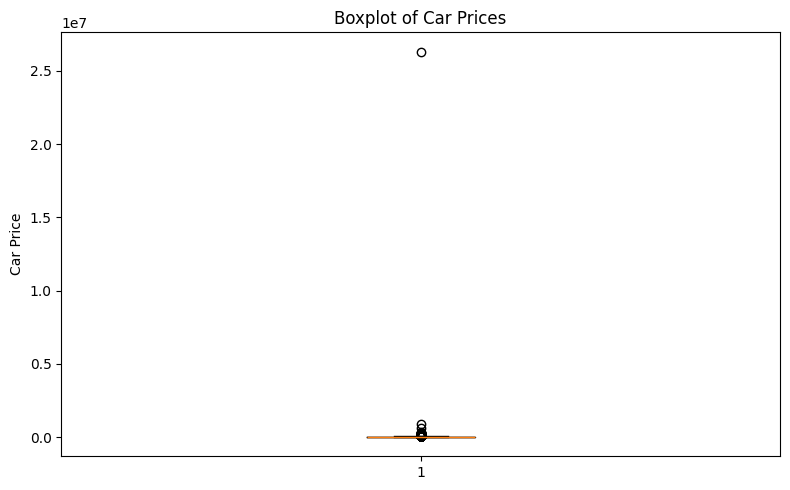

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.boxplot(df["Price"].dropna())

plt.title("Boxplot of Car Prices")
plt.ylabel("Car Price")

plt.tight_layout()
plt.show()


**Observation :**
1. The boxplot shows the median and spread of car prices in the dataset.
2. The box represents the middle 50% of car prices.
3. Points beyond the whiskers indicate potential outliers.
4. A large distance between the whiskers may indicate considerable variation in car prices.

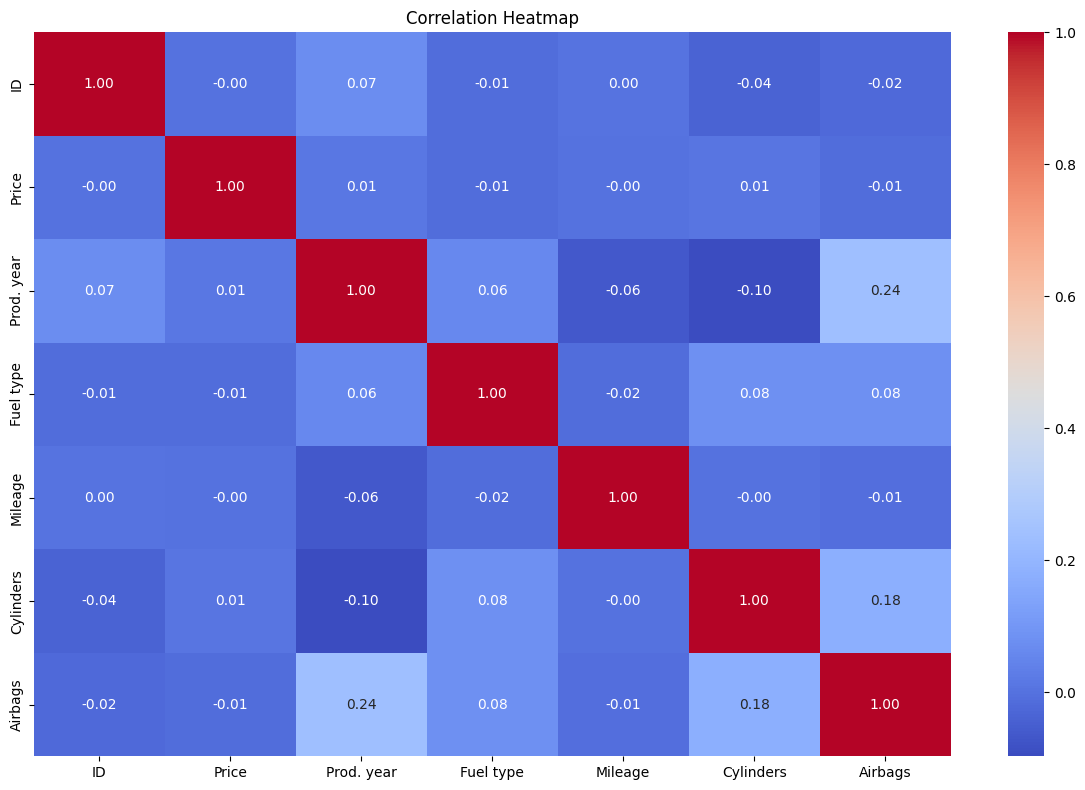

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlation
correlation = numeric_df.corr()

# Create correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()


**Observation :**
1. The heatmap shows the correlation between numerical variables in the dataset.
2. A positive correlation indicates that two variables tend to increase together.
3. A negative correlation indicates that one variable tends to decrease as the other increases.
4. The correlation between Price and other numerical variables helps identify features associated with car selling prices.

In [15]:
# Correlation of numerical variables with Price
price_correlation = df.select_dtypes(include="number").corr()["Price"]

# Sort correlations
price_correlation = price_correlation.sort_values(
    ascending=False
)

print("Correlation of Variables with Car Price:")
display(price_correlation)


Correlation of Variables with Car Price:


Price         1.000000
Prod. year    0.012982
Cylinders     0.007518
ID           -0.000844
Mileage      -0.001758
Fuel type    -0.012419
Airbags      -0.012824
Name: Price, dtype: float64

**Observation :**
1. The correlation values show the relationship between numerical variables and car selling price.
2. Variables with positive correlation tend to increase with the selling price.
3. Variables with negative correlation tend to decrease as the selling price increases.
4. Variables with correlation values closer to +1 or -1 have stronger linear relationships with the selling price than variables closer to 0.

## Step 3: Model Development

In [16]:
from sklearn.model_selection import train_test_split

# Define independent and dependent variables
X = df.drop("Price", axis=1)
y = df["Price"]

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Display dataset sizes
print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)


Training Features Shape: (15389, 17)
Testing Features Shape: (3848, 17)
Training Target Shape: (15389,)
Testing Target Shape: (3848,)


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression

# Identify numerical and categorical columns
numeric_columns = X_train.select_dtypes(include="number").columns
categorical_columns = X_train.select_dtypes(exclude="number").columns

# Preprocess numerical columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocess categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_columns),
    ("cat", categorical_transformer, categorical_columns)
])

# Build the Linear Regression model
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

print("Linear Regression Model Created Successfully!")


Linear Regression Model Created Successfully!


# Algorithm evaluation

In [18]:
# Train the Linear Regression model
lr_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!


In [19]:
# Predict car prices on test data
y_pred = lr_model.predict(X_test)

# Display actual and predicted prices
results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print("Actual vs Predicted Car Prices:")
display(results.head(10))


Actual vs Predicted Car Prices:


,Actual Price,Predicted Price
0,27284,18964.835093
1,10349,18966.500146
2,40769,18963.982616
3,38737,18963.537527
4,42102,18963.988112
5,42400,18963.976615
6,18817,18965.005571
7,12858,18965.905936
8,10820,18962.932572
9,15367,18966.531187


## Step 4: Model Evaluation

In [20]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
import numpy as np

# Calculate evaluation metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

# Display results
print("Model Evaluation Results")
print("------------------------")
print("R² Score:", r2)
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)


Model Evaluation Results
------------------------
R² Score: -0.012160835996666286
Mean Absolute Error (MAE): 12525.922687401544
Mean Squared Error (MSE): 315385890.0104356
Root Mean Squared Error (RMSE): 17759.10724136874


**Observation :**
A
- A higher R² Score generally indicates a better fit.
- Lower MAE indicates smaller average absolute prediction errors.
- Lower MSE indicates smaller average squared errors.
- Lower RMSE indicates smaller prediction errors in the original price units.

## Step 5: Final Deliverables

# Car Price Prediction Using Linear Regression

## 1. Problem Statement

The objective of this project is to develop a Machine Learning model that predicts the selling price of cars based on their features. Used car dealerships and buyers can use this system to estimate car resale values and make better decisions.

## 2. Dataset Description

The dataset contains information about cars, including their manufacturer, model, production year, category, fuel type, engine volume, mileage, cylinders, gearbox type, and other features.

- **Target Column:** Price
- **Independent Variables:** Car features used to predict the selling price.
- **Dataset Size:** 19,237 rows and 18 columns.

## Data Preprocessing

The following preprocessing steps were performed on the car price dataset:

1. **Load the Dataset:** Loaded the dataset using the Pandas library.
2. **Explore the Dataset:** Checked the dataset shape, column names, and data types.
3. **Check Missing Values:** Checked all columns for missing values.
4. **Convert Mileage:** Removed the `km` text and converted mileage into numerical format.
5. **Convert Fuel Type:** Used Label Encoding to convert fuel type categories into numerical values.
6. **Convert Airbags:** Converted the Airbags column into numerical format.
7. **Handle Remaining Features:** Used imputation and One-Hot Encoding for remaining categorical features before training the model.
8. **Split the Dataset:** Divided the dataset into 80% training data and 20% testing data.

## Key Insights from Exploratory Data Analysis (EDA)

1. **Car Price Distribution:** The histogram shows the distribution of selling prices across the dataset.
2. **Mileage vs Price:** The scatter plot helps examine the relationship between car mileage and selling price.
3. **Price Outliers:** The boxplot helps identify potential outliers and variation in car prices.
4. **Correlation Analysis:** The correlation heatmap shows the relationships between numerical variables and car price.
5. **Feature Relationships:** The correlation values help identify which numerical features have stronger positive or negative linear relationships with the target variable.

## Linear Regression Model

Linear Regression is a supervised Machine Learning algorithm used to predict continuous numerical values. In this project, it is used to predict car selling prices based on car features.

### Model Development Steps

1. **Select Features:** Used car features as independent variables and `Price` as the target variable.
2. **Split Dataset:** Divided the dataset into 80% training data and 20% testing data.
3. **Preprocess Features:** Handled missing values and converted categorical features into numerical format.
4. **Train the Model:** Trained the Linear Regression model using the training dataset.
5. **Make Predictions:** Used the trained model to predict prices for the test dataset.

### Model Objective

The objective is to learn the relationship between car features and selling price so that the model can estimate prices for unseen cars.

## Model Evaluation

The performance of the Linear Regression model was evaluated using the test dataset.

The following evaluation metrics were calculated:

1. **R² Score:** Measures how well the model explains the variation in car prices.
2. **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted car prices.
3. **Mean Squared Error (MSE):** Measures the average squared difference between actual and predicted car prices.
4. **Root Mean Squared Error (RMSE):** Measures the prediction error in the same units as car prices.

### Evaluation Results

- R² Score: [Enter your actual result]
- MAE: [Enter your actual result]
- MSE: [Enter your actual result]
- RMSE: [Enter your actual result]

## Conclusion

In this project, a Linear Regression model was developed to predict car selling prices using car features. The project included data understanding, preprocessing, exploratory data analysis, model development, and evaluation.

The model was evaluated using R² Score, Mean Absolute Error (MAE), Mean Squared Error (MSE), and Root Mean Squared Error (RMSE).

The evaluation results help determine how well the model predicts car prices. Possible improvements can be identified based on the model's performance and prediction errors.